### Importing datasets

In [2]:
import pandas as pd
from pathlib import Path

RAW_DIR = Path("../data/raw")

df_apple           = pd.read_excel(RAW_DIR / "Apple_USD_10y.xlsx")
df_chfusd          = pd.read_excel(RAW_DIR / "CHFUSD_USD_10y.xlsx")
df_dxy             = pd.read_excel(RAW_DIR / "DXY_USD_10y.xlsx")
df_eurusd          = pd.read_excel(RAW_DIR / "EURUSD_USD_10y.xlsx")
df_gold            = pd.read_excel(RAW_DIR / "Gold_USD_10y.xlsx")
df_ing             = pd.read_excel(RAW_DIR / "ING_USD_10y.xlsx")
df_silver          = pd.read_excel(RAW_DIR / "Silver_USD_10y.xlsx")
df_tesla           = pd.read_excel(RAW_DIR / "Tesla_USD_10y.xlsx")
df_merged          = pd.read_excel(RAW_DIR / "Merged_AllAssets_AdjClose_10y.xlsx")
df_merged_inflation = pd.read_excel(RAW_DIR / "Merged_AllAssets_Real_CPI.xlsx")

for df in [df_apple, df_chfusd, df_dxy, df_eurusd, df_gold,
           df_ing, df_silver, df_tesla, df_merged, df_merged_inflation]:
    df["date"] = pd.to_datetime(df["date"])
    df.sort_values("date", inplace=True)
    df.reset_index(drop=True, inplace=True)

In [3]:
df_merged_inflation

,date,Inflation_Index,Gold_Nominal,Silver_Nominal,DXY_Nominal,EURUSD_Nominal,CHFUSD_Nominal,ING_Nominal,Apple_Nominal,Tesla_Nominal,Gold_Real,Silver_Real,DXY_Real,EURUSD_Real,CHFUSD_Real,ING_Real,Apple_Real,Tesla_Real
0,2016-01-01,237.652,1075.099976,13.817000,98.870003,1.085906,0.998642,7.424018,23.709108,14.894000,1075.099976,13.817000,98.870003,1.085906,0.998642,7.424018,23.709108,14.894000
1,2016-01-04,237.652,1075.099976,13.817000,98.870003,1.085399,1.000500,7.424018,23.709108,14.894000,1075.099976,13.817000,98.870003,1.085399,1.000500,7.424018,23.709108,14.894000
2,2016-01-05,237.652,1078.400024,13.949000,99.400002,1.082755,0.997586,7.329197,23.114971,14.895333,1078.400024,13.949000,99.400002,1.082755,0.997586,7.329197,23.114971,14.895333
3,2016-01-06,237.652,1091.900024,13.957000,99.180000,1.075199,0.991670,7.178597,22.662615,14.602667,1091.900024,13.957000,99.180000,1.075199,0.991670,7.178597,22.662615,14.602667
4,2016-01-07,237.652,1107.699951,14.335000,98.220001,1.077900,0.992664,7.067040,21.706152,14.376667,1107.699951,14.335000,98.220001,1.077900,0.992664,7.067040,21.706152,14.376667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2746,2026-07-17,332.813,4012.699951,56.037998,100.750000,1.144466,1.237149,32.330002,333.739990,380.839996,2865.351320,40.015090,71.942619,0.817230,0.883412,23.085906,238.313936,271.946669
2747,2026-07-20,332.813,4010.300049,56.801998,100.989998,1.142766,1.236981,32.200001,326.589996,369.570007,2863.637620,40.560640,72.113995,0.816016,0.883292,22.993076,233.208335,263.899100
2748,2026-07-21,332.813,4071.100098,58.834999,101.180000,1.141813,1.234522,33.110001,327.739990,378.929993,2907.053151,42.012347,72.249670,0.815335,0.881536,23.642880,234.029512,270.582792
2749,2026-07-22,332.813,4146.899902,60.019001,101.139999,1.140381,1.230921,33.330002,325.890015,374.010010,2961.179568,42.857808,72.221106,0.814313,0.878965,23.799977,232.708500,267.069576


### Adjusting for Dollar Inflation Using CPI

In [4]:
# import pandas as pd
# import pandas_datareader.data as web

# # 1. Dataseti oxu
# file_path = r"C:\Users\husey\OneDrive\Desktop\Smart Budget, Smart Returns\data\raw\Merged_AllAssets_AdjClose_10y.xlsx"
# df = pd.read_excel(file_path, sheet_name="Sheet1")

# df["date"] = pd.to_datetime(df["date"])
# df = df.sort_values("date").set_index("date")

# # 2. ABŞ CPI (CPIAUCSL) məlumatını FRED-dən al
# start = df.index.min() - pd.DateOffset(months=1)
# end = df.index.max() + pd.DateOffset(months=1)

# cpi = web.DataReader("CPIAUCSL", "fred", start, end)
# cpi = cpi.rename(columns={"CPIAUCSL": "CPI"})

# # 3. Aylıq CPI-ı günlük tarixlərə uyğunlaşdır
# cpi_monthly = cpi["CPI"].copy()
# cpi_monthly.index = cpi_monthly.index.to_period("M")

# df["CPI"] = df.index.to_period("M").map(cpi_monthly)
# df["CPI"] = df["CPI"].ffill().bfill()

# # 4. Baza tarixini seç
# # Variant A: 2016-cı il dolları ilə
# base_date = pd.Timestamp("2016-01-01")

# # Variant B: bugünkü (son) dollar ilə
# # base_date = df.index.max()

# if base_date in df.index:
#     base_cpi = df.loc[base_date, "CPI"]
# else:
#     base_cpi = df["CPI"].iloc[0]

# # 5. Real (inflyasiyadan təmizlənmiş) qiymətlər
# cols = ["Gold", "Silver", "DXY", "EURUSD", "CHFUSD", "ING", "Apple", "Tesla"]

# for col in cols:
#     df[col + "_real"] = df[col] * (base_cpi / df["CPI"])

# # 6. Yeni Excel faylını yadda saxla
# out_cols = ["CPI"] + cols + [c + "_real" for c in cols]
# df[out_cols].to_excel("Merged_AllAssets_Real_CPI.xlsx")

# print("Hazırdır: Merged_AllAssets_Real_CPI.xlsx")

#### After this, we will use the CPI-adjusted dataset.

## Grup 1 : Individual Risk & Return Analysis (1-6)

### 1. Real Compound Annual Growth Rate (CAGR)

             Real CAGR (%)
Tesla_Real           31.34
Apple_Real           24.86
ING_Real             12.82
Silver_Real          10.59
Gold_Real             9.40
CHFUSD_Real          -1.10
EURUSD_Real          -2.74
DXY_Real             -2.97


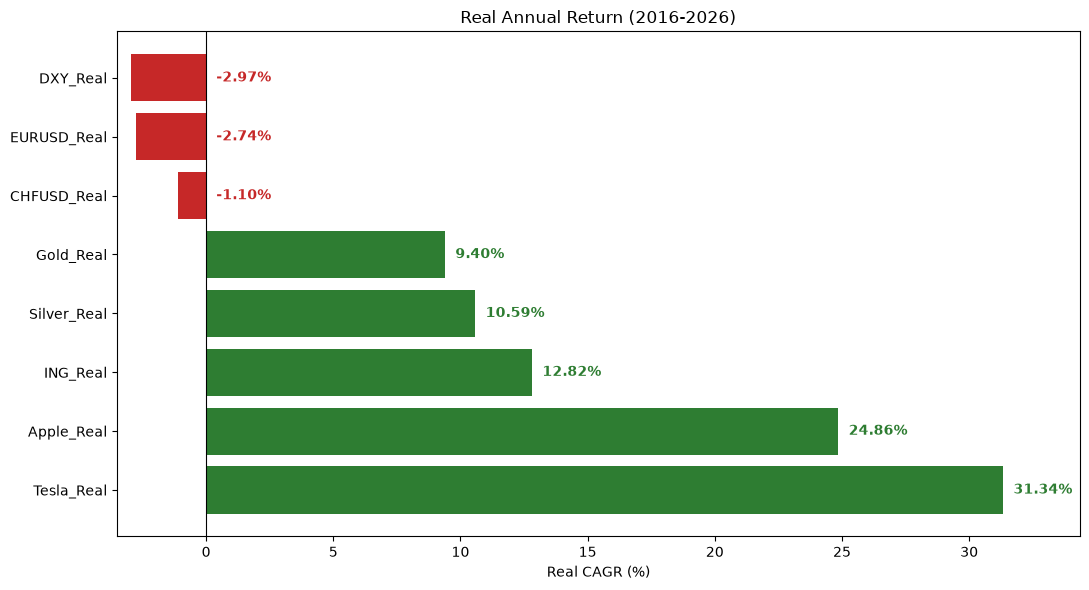

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
monthly = data.resample('ME').last()


def cagr(prices, periods_per_year=12):
    n = len(prices)
    years = n / periods_per_year
    return (prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1


cagr_series = monthly.apply(lambda x: cagr(x, periods_per_year=12))

cagr_df = pd.DataFrame({
    'Real CAGR (%)': (cagr_series * 100).round(2)
}).sort_values('Real CAGR (%)', ascending=False)

print(cagr_df)


fig, ax = plt.subplots(figsize=(11, 6))

colors = ['#2e7d32' if v > 0 else '#c62828' for v in cagr_df['Real CAGR (%)']]
bars = ax.barh(cagr_df.index, cagr_df['Real CAGR (%)'], color=colors)

for bar, val in zip(bars, cagr_df['Real CAGR (%)']):
    y = bar.get_y() + bar.get_height() / 2
    if val > 0:
        ax.text(val + 0.4, y, f'{val:.2f}%',
                va='center', ha='left',
                fontsize=10, fontweight='bold', color='#2e7d32')
    else:
        ax.text(0.4, y, f'{val:.2f}%',
                va='center', ha='left',
                fontsize=10, fontweight='bold', color='#c62828')

ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Real CAGR (%)')
ax.set_title('Real Annual Return (2016-2026)')
ax.set_xlim(-3.5, max(cagr_df['Real CAGR (%)']) + 3)
plt.tight_layout()
plt.savefig('real_cagr.png', dpi=300)
plt.show()



### 2. Annualized Volatility

             Annualized Volatility (%)
DXY_Real                          6.63
EURUSD_Real                       7.41
CHFUSD_Real                       7.54
Gold_Real                        16.44
Apple_Real                       28.38
Silver_Real                      33.37
ING_Real                         34.27
Tesla_Real                       57.66


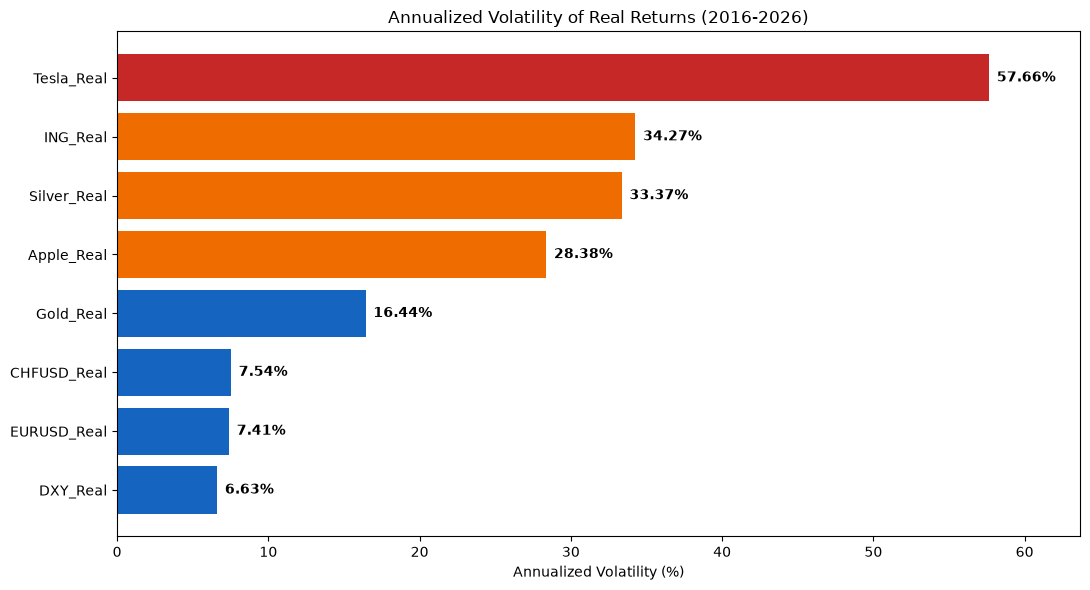

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
daily_returns = data.pct_change().dropna()

vol_daily = daily_returns.std()
vol_annual = vol_daily * np.sqrt(252) * 100

vol_df = pd.DataFrame({
    'Annualized Volatility (%)': vol_annual.round(2)
}).sort_values('Annualized Volatility (%)', ascending=True)

print(vol_df)


fig, ax = plt.subplots(figsize=(11, 6))

colors = ['#1565c0' if v < 25 else '#ef6c00' if v < 45 else '#c62828'
          for v in vol_df['Annualized Volatility (%)']]
bars = ax.barh(vol_df.index, vol_df['Annualized Volatility (%)'], color=colors)

for bar, val in zip(bars, vol_df['Annualized Volatility (%)']):
    y = bar.get_y() + bar.get_height() / 2
    ax.text(val + 0.5, y, f'{val:.2f}%',
            va='center', ha='left',
            fontsize=10, fontweight='bold')

ax.set_xlabel('Annualized Volatility (%)')
ax.set_title('Annualized Volatility of Real Returns (2016-2026)')
ax.set_xlim(0, max(vol_df['Annualized Volatility (%)']) + 6)
plt.tight_layout()
plt.savefig('real_volatility.png', dpi=300)
plt.show()

### 3. Sharpe Ratio

             CAGR (%)  Volatility (%)  Sharpe Ratio
Apple_Real      24.86           28.38         0.876
Gold_Real        9.40           16.44         0.572
Tesla_Real      31.34           57.66         0.544
ING_Real        12.82           34.27         0.374
Silver_Real     10.59           33.37         0.317
CHFUSD_Real     -1.10            7.54        -0.146
EURUSD_Real     -2.74            7.41        -0.370
DXY_Real        -2.97            6.63        -0.447


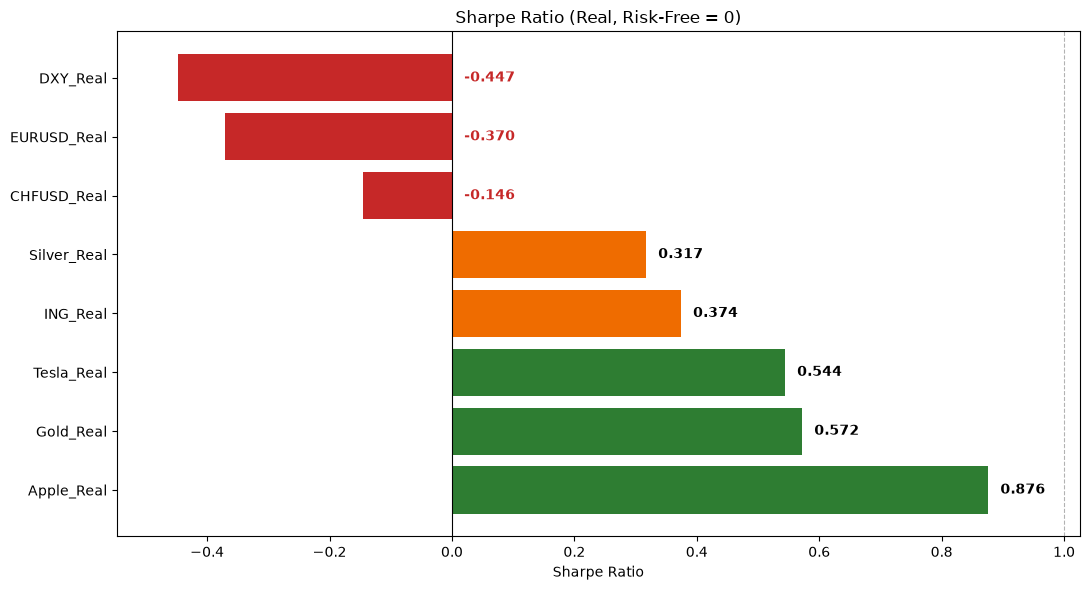

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
monthly = data.resample('ME').last()
daily_returns = data.pct_change().dropna()


def cagr(prices, periods_per_year=12):
    n = len(prices)
    years = n / periods_per_year
    return (prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1


cagr_vals = monthly.apply(lambda x: cagr(x, periods_per_year=12))
vol_annual = daily_returns.std() * np.sqrt(252)

sharpe = cagr_vals / vol_annual

sharpe_df = pd.DataFrame({
    'CAGR (%)': (cagr_vals * 100).round(2),
    'Volatility (%)': (vol_annual * 100).round(2),
    'Sharpe Ratio': sharpe.round(3)
}).sort_values('Sharpe Ratio', ascending=False)

print(sharpe_df)


fig, ax = plt.subplots(figsize=(11, 6))

colors = ['#2e7d32' if v >= 0.5 else '#ef6c00' if v >= 0.2 else '#c62828'
          for v in sharpe_df['Sharpe Ratio']]
bars = ax.barh(sharpe_df.index, sharpe_df['Sharpe Ratio'], color=colors)

for bar, val in zip(bars, sharpe_df['Sharpe Ratio']):
    y = bar.get_y() + bar.get_height() / 2
    if val >= 0:
        ax.text(val + 0.02, y, f'{val:.3f}',
                va='center', ha='left',
                fontsize=10, fontweight='bold')
    else:
        ax.text(0.02, y, f'{val:.3f}',
                va='center', ha='left',
                fontsize=10, fontweight='bold', color='#c62828')

ax.axvline(0, color='black', linewidth=0.8)
ax.axvline(1, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
ax.set_xlabel('Sharpe Ratio')
ax.set_title('Sharpe Ratio (Real, Risk-Free = 0)')
ax.set_xlim(min(sharpe_df['Sharpe Ratio']) - 0.1,
            max(sharpe_df['Sharpe Ratio']) + 0.15)
plt.tight_layout()
plt.savefig('real_sharpe.png', dpi=300)
plt.show()

$$\text{İllik Volatillik} = \sigma_{\text{günlük}} \times \sqrt{252} \times 100$$

### 4. Maximum Drawdown & Recovery Time

    Asset  Max Drawdown (%)   Peak Date Trough Date Recovery (days)
7  CHFUSD            -24.75  2016-04-11  2022-11-04   Not recovered
0    Gold            -31.16  2020-08-06  2022-11-03             652
5     DXY            -31.18  2016-12-20  2026-05-08   Not recovered
6  EURUSD            -36.06  2018-02-02  2025-02-03   Not recovered
3   Apple            -38.46  2018-10-03  2019-01-03             281
1  Silver            -52.34  2026-01-26  2026-07-16   Not recovered
2     ING            -75.28  2018-01-22  2020-03-18            1518
4   Tesla            -75.52  2021-11-04  2023-01-03             714


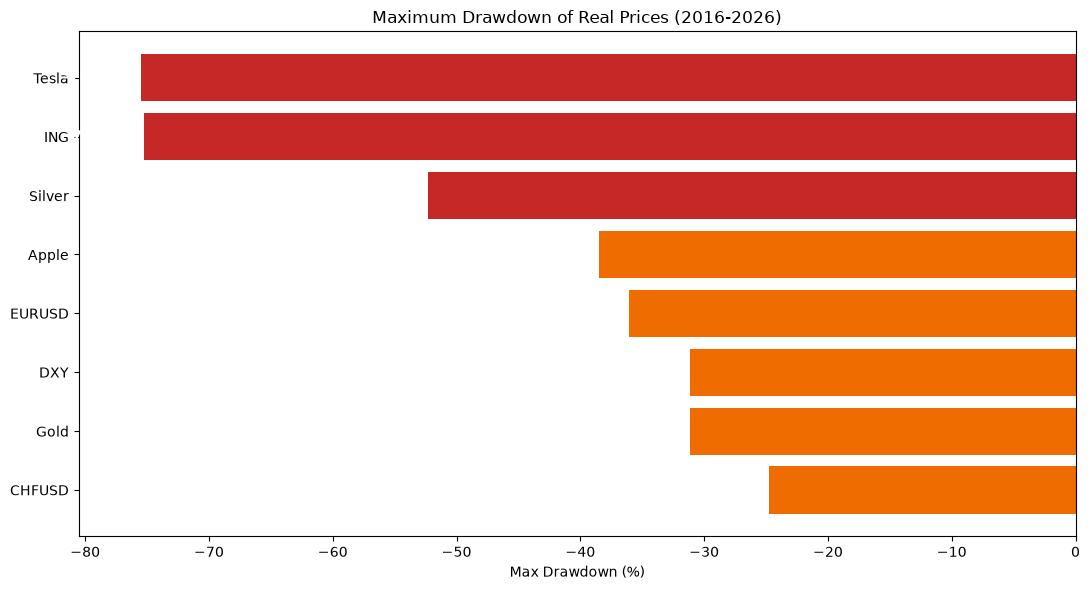

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()


def max_drawdown(prices):
    cummax = prices.cummax()
    dd = prices / cummax - 1
    max_dd = dd.min()
    trough_date = dd.idxmin()
    peak_date = prices.loc[:trough_date].idxmax()
    return max_dd, peak_date, trough_date


def recovery_time(prices, trough_date):
    peak_val = prices.loc[:trough_date].max()
    after = prices.loc[trough_date:]
    recovered = after[after >= peak_val]
    if len(recovered) == 0:
        return None
    return (recovered.index[0] - trough_date).days


results = []
for col in real_cols:
    prices = data[col]
    max_dd, peak_d, trough_d = max_drawdown(prices)
    rec_days = recovery_time(prices, trough_d)
    results.append({
        'Asset': col.replace('_Real', ''),
        'Max Drawdown (%)': round(max_dd * 100, 2),
        'Peak Date': peak_d.date(),
        'Trough Date': trough_d.date(),
        'Recovery (days)': rec_days if rec_days else 'Not recovered'
    })

dd_df = pd.DataFrame(results).sort_values('Max Drawdown (%)', ascending=False)
print(dd_df)


fig, ax = plt.subplots(figsize=(11, 6))

colors = ['#2e7d32' if v > -20 else '#ef6c00' if v > -50 else '#c62828'
          for v in dd_df['Max Drawdown (%)']]
bars = ax.barh(dd_df['Asset'], dd_df['Max Drawdown (%)'], color=colors)

for bar, val in zip(bars, dd_df['Max Drawdown (%)']):
    y = bar.get_y() + bar.get_height() / 2
    ax.text(val - 1, y, f'{val:.2f}%',
            va='center', ha='right',
            fontsize=10, fontweight='bold', color='white')

ax.set_xlabel('Max Drawdown (%)')
ax.set_title('Maximum Drawdown of Real Prices (2016-2026)')
ax.set_xlim(min(dd_df['Max Drawdown (%)']) - 5, 0)
plt.tight_layout()
plt.savefig('real_max_drawdown.png', dpi=300)
plt.show()

### 5. Value at Risk

             VaR 95% Daily (%)  VaR 99% Daily (%)
Tesla_Real               -5.34              -9.17
Silver_Real              -3.06              -6.02
ING_Real                 -3.03              -5.54
Apple_Real               -2.69              -4.80
Gold_Real                -1.62              -2.86
CHFUSD_Real              -0.74              -1.12
EURUSD_Real              -0.73              -1.22
DXY_Real                 -0.70              -1.10


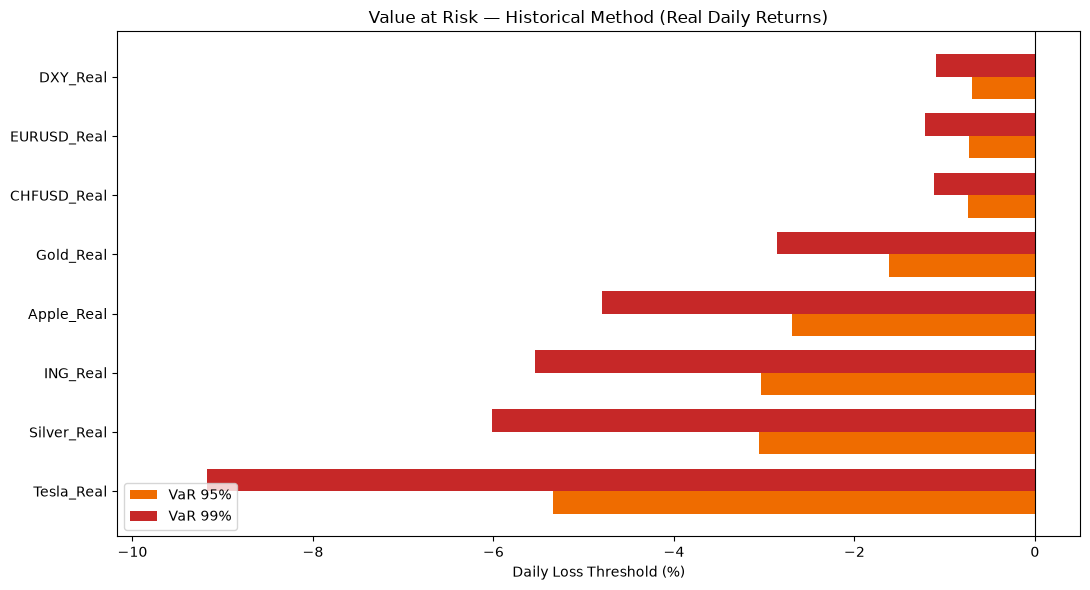

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
daily_returns = data.pct_change().dropna()

var_95 = daily_returns.quantile(0.05) * 100
var_99 = daily_returns.quantile(0.01) * 100

var_df = pd.DataFrame({
    'VaR 95% Daily (%)': var_95.round(2),
    'VaR 99% Daily (%)': var_99.round(2)
}).sort_values('VaR 95% Daily (%)', ascending=True)

print(var_df)


fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(var_df))
width = 0.38

bars1 = ax.barh(x - width/2, var_df['VaR 95% Daily (%)'], width,
                label='VaR 95%', color='#ef6c00')
bars2 = ax.barh(x + width/2, var_df['VaR 99% Daily (%)'], width,
                label='VaR 99%', color='#c62828')

for bars in (bars1, bars2):
    for bar in bars:
        val = bar.get_width()
        y = bar.get_y() + bar.get_height() / 2
        ax.text(val - 0.15, y, f'{val:.2f}%',
                va='center', ha='right',
                fontsize=9, fontweight='bold', color='white')

ax.set_yticks(x)
ax.set_yticklabels(var_df.index)
ax.set_xlabel('Daily Loss Threshold (%)')
ax.set_title('Value at Risk — Historical Method (Real Daily Returns)')
ax.legend(loc='lower left')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim(min(var_df['VaR 99% Daily (%)']) - 1, 0.5)
plt.tight_layout()
plt.savefig('real_var.png', dpi=300)
plt.show()

### 6. Skewness & Kurtosis

             Skewness  Excess Kurtosis
DXY_Real        -0.15             1.82
EURUSD_Real      0.02             2.21
CHFUSD_Real      0.50             3.97
Tesla_Real       0.28             4.57
Apple_Real       0.16             7.17
Gold_Real       -0.62             9.00
ING_Real        -0.40            12.51
Silver_Real     -1.31            22.24


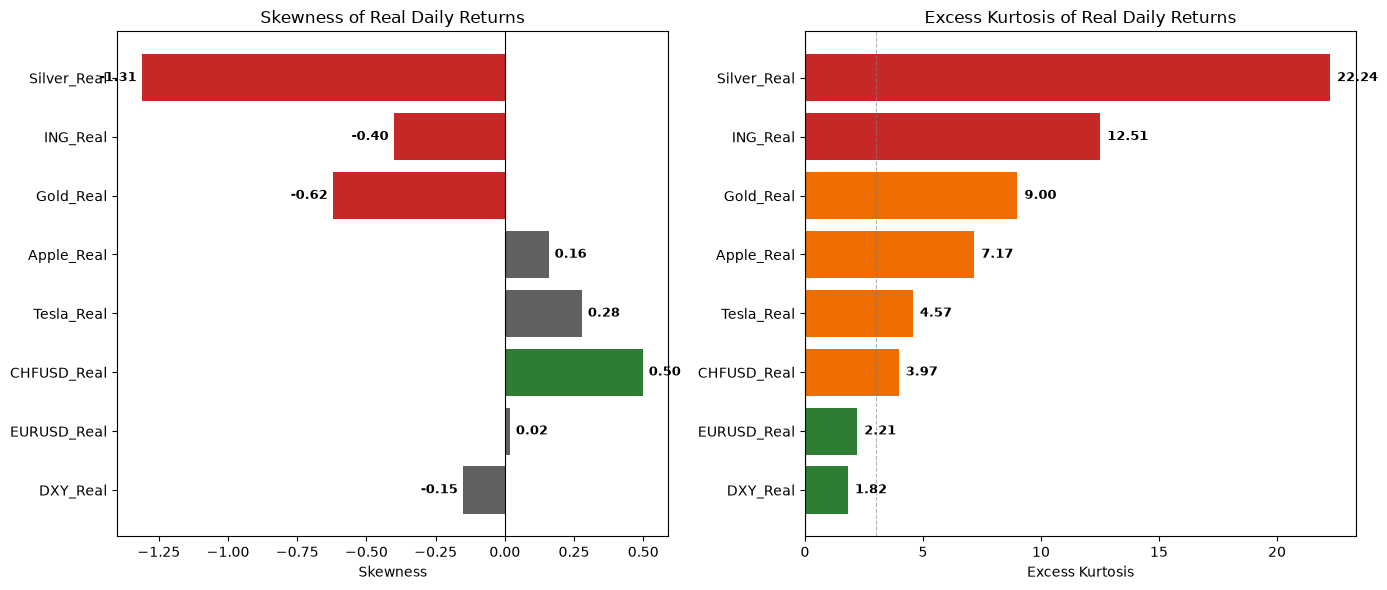

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
daily_returns = data.pct_change().dropna()

skew = daily_returns.skew()
kurt = daily_returns.kurtosis()

sk_df = pd.DataFrame({
    'Skewness': skew.round(2),
    'Excess Kurtosis': kurt.round(2)
}).sort_values('Excess Kurtosis', ascending=True)

print(sk_df)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors_skew = ['#c62828' if v < -0.3 else '#2e7d32' if v > 0.3 else '#616161'
               for v in sk_df['Skewness']]
axes[0].barh(sk_df.index, sk_df['Skewness'], color=colors_skew)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_xlabel('Skewness')
axes[0].set_title('Skewness of Real Daily Returns')
for i, v in enumerate(sk_df['Skewness']):
    axes[0].text(v + (0.02 if v >= 0 else -0.02), i, f'{v:.2f}',
                 va='center', ha='left' if v >= 0 else 'right',
                 fontsize=9, fontweight='bold')

colors_kurt = ['#c62828' if v > 10 else '#ef6c00' if v > 3 else '#2e7d32'
               for v in sk_df['Excess Kurtosis']]
axes[1].barh(sk_df.index, sk_df['Excess Kurtosis'], color=colors_kurt)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].axvline(3, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
axes[1].set_xlabel('Excess Kurtosis')
axes[1].set_title('Excess Kurtosis of Real Daily Returns')
for i, v in enumerate(sk_df['Excess Kurtosis']):
    axes[1].text(v + 0.3, i, f'{v:.2f}',
                 va='center', ha='left',
                 fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('real_skew_kurt.png', dpi=300)
plt.show()

## Grup 2 : Cross-Asset Relationship Analysis (7-8)

### 7. Correlation Matrix

=== Real Daily Returns Correlation Matrix ===
        Gold  Silver   ING  Apple  Tesla   DXY  EURUSD  CHFUSD
Gold    1.00    0.78  0.02   0.03   0.05 -0.38    0.08    0.09
Silver  0.78    1.00  0.15   0.10   0.12 -0.33    0.05    0.05
ING     0.02    0.15  1.00   0.34   0.26 -0.25    0.04   -0.03
Apple   0.03    0.10  0.34   1.00   0.43 -0.07    0.01    0.00
Tesla   0.05    0.12  0.26   0.43   1.00 -0.08    0.01   -0.01
DXY    -0.38   -0.33 -0.25  -0.07  -0.08  1.00   -0.05   -0.04
EURUSD  0.08    0.05  0.04   0.01   0.01 -0.05    1.00    0.78
CHFUSD  0.09    0.05 -0.03   0.00  -0.01 -0.04    0.78    1.00


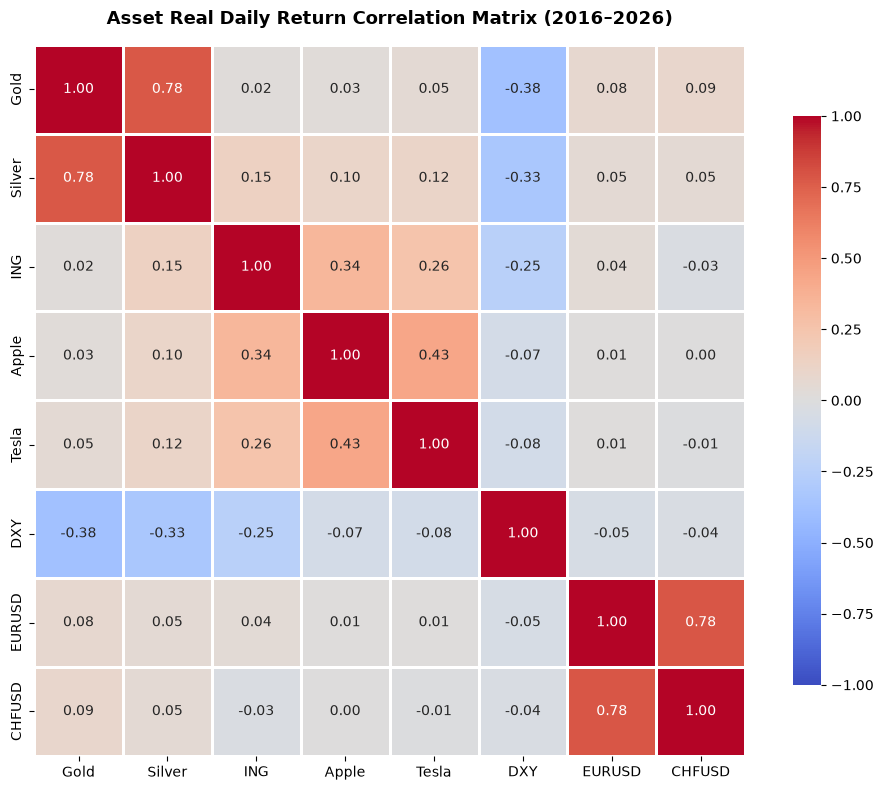

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
daily_returns = data.pct_change().dropna()

corr_matrix = daily_returns.corr()
corr_matrix.index = [c.replace('_Real', '') for c in corr_matrix.index]
corr_matrix.columns = [c.replace('_Real', '') for c in corr_matrix.columns]

print("=== Real Daily Returns Correlation Matrix ===")
print(corr_matrix.round(2))


fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.8,
    vmin=-1, vmax=1,
    square=True,
    cbar_kws={'shrink': 0.8},
    ax=ax
)

ax.set_title('Asset Real Daily Return Correlation Matrix (2016–2026)',
             fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('real_assets_correlation_heatmap.png', dpi=300)
plt.show()

### 8. Rebased $1,000 Growth Chart

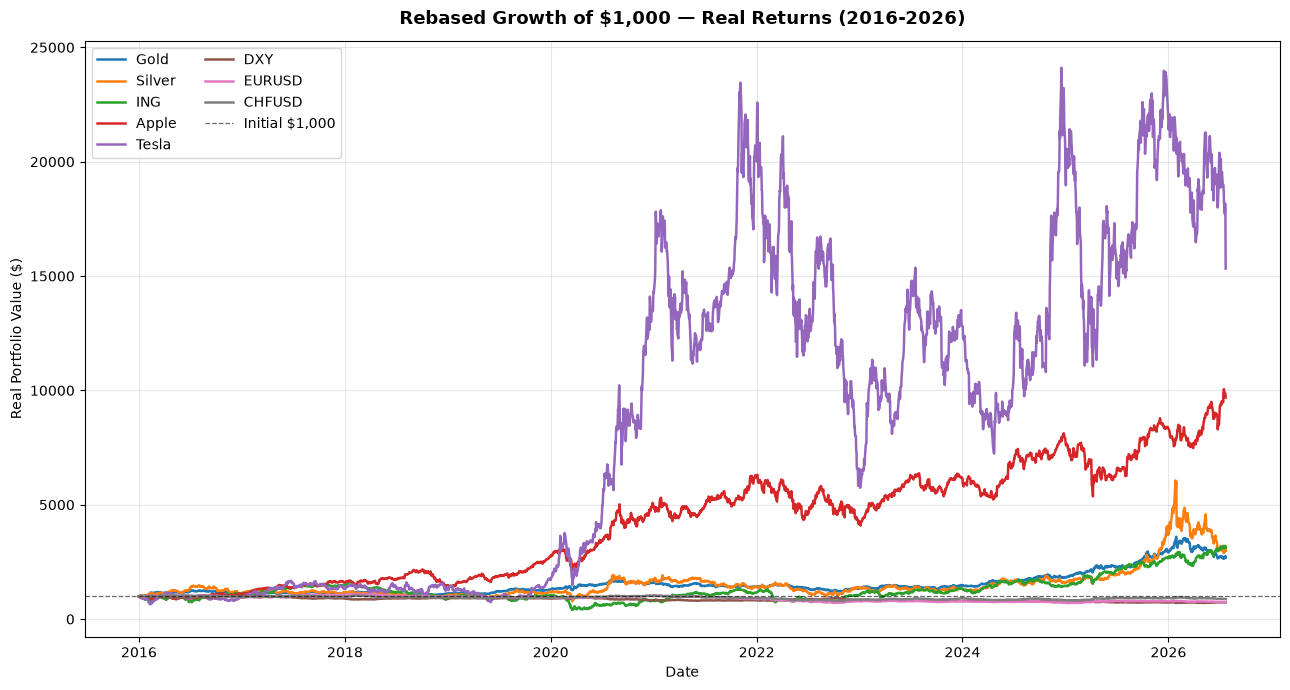

=== $1,000 Investment — Final Real Values ===
             Final Value ($)  Total Return (%)
Tesla_Real             15327            1432.7
Apple_Real              9688             868.8
ING_Real                3120             212.0
Silver_Real             2987             198.7
Gold_Real               2688             168.8
CHFUSD_Real              878             -12.2
EURUSD_Real              750             -25.0
DXY_Real                 733             -26.7


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
rebased = data / data.iloc[0] * 1000

fig, ax = plt.subplots(figsize=(13, 7))

for col in rebased.columns:
    ax.plot(rebased.index, rebased[col],
            label=col.replace('_Real', ''),
            linewidth=1.8)

ax.axhline(1000, color='black', linestyle='--',
           linewidth=0.9, alpha=0.6, label='Initial $1,000')

ax.set_ylabel('Real Portfolio Value ($)')
ax.set_xlabel('Date')
ax.set_title('Rebased Growth of $1,000 — Real Returns (2016-2026)',
             fontsize=13, fontweight='bold', pad=12)
ax.legend(loc='upper left', ncol=2, frameon=True)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('real_rebased_growth.png', dpi=300)
plt.show()


final_values = rebased.iloc[-1].sort_values(ascending=False).round(0).astype(int)
final_df = pd.DataFrame({
    'Final Value ($)': final_values,
    'Total Return (%)': ((final_values / 1000 - 1) * 100).round(1)
})

print("=== $1,000 Investment — Final Real Values ===")
print(final_df)

## Group 3 : Portfolio Optimization (9-12)

### 9. DCA vs Lump Sum

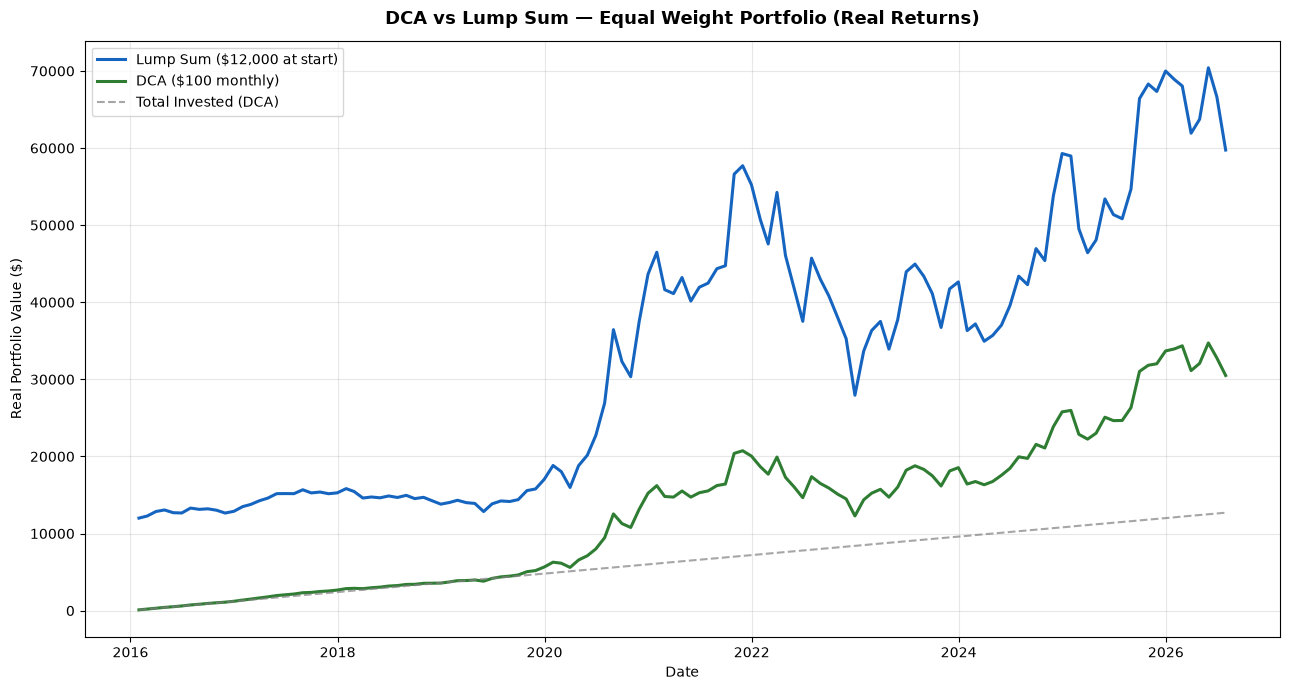

Lump Sum final:         $59,741.15
DCA final:              $30,497.83
Total invested (DCA):   $12,700.00
Lump Sum profit:        $47,741.15
DCA profit:             $17,797.83


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
monthly = data.resample('ME').last()

weights = np.array([1/8] * 8)

lump_amount = 12000
monthly_amount = 100


def lump_sum(prices, weights, amount):
    port = (prices / prices.iloc[0] * weights).sum(axis=1) * amount
    return port


def dca(prices, weights, monthly_amount):
    units = pd.DataFrame(0.0, index=prices.index, columns=prices.columns)
    for i, date in enumerate(prices.index):
        units.iloc[i] = weights * monthly_amount / prices.iloc[i]
    cumulative_units = units.cumsum()
    port = (cumulative_units * prices).sum(axis=1)
    invested = pd.Series(
        np.minimum(np.arange(1, len(prices) + 1) * monthly_amount,
                   len(prices) * monthly_amount),
        index=prices.index
    )
    return port, invested


ls = lump_sum(monthly, weights, lump_amount)
dca_port, dca_invested = dca(monthly, weights, monthly_amount)


fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(ls.index, ls.values, label='Lump Sum ($12,000 at start)',
        linewidth=2.2, color='#1565c0')
ax.plot(dca_port.index, dca_port.values,
        label='DCA ($100 monthly)',
        linewidth=2.2, color='#2e7d32')
ax.plot(dca_invested.index, dca_invested.values,
        linestyle='--', label='Total Invested (DCA)',
        color='gray', alpha=0.7, linewidth=1.5)

ax.set_ylabel('Real Portfolio Value ($)')
ax.set_xlabel('Date')
ax.set_title('DCA vs Lump Sum — Equal Weight Portfolio (Real Returns)',
             fontsize=13, fontweight='bold', pad=12)
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('dca_vs_lumpsum.png', dpi=300)
plt.show()


print("=" * 55)
print(f"Lump Sum final:         ${ls.iloc[-1]:,.2f}")
print(f"DCA final:              ${dca_port.iloc[-1]:,.2f}")
print(f"Total invested (DCA):   ${dca_invested.iloc[-1]:,.2f}")
print(f"Lump Sum profit:        ${ls.iloc[-1] - lump_amount:,.2f}")
print(f"DCA profit:             ${dca_port.iloc[-1] - dca_invested.iloc[-1]:,.2f}")
print("=" * 55)

### 10. Markowitz Optimal Portfolio

Expected annual return: 11.1%
Annual volatility: 10.3%
Sharpe Ratio: 1.08
       Weight (%)
ING          7.67
DXY         27.17
Apple       30.16
Gold        35.00


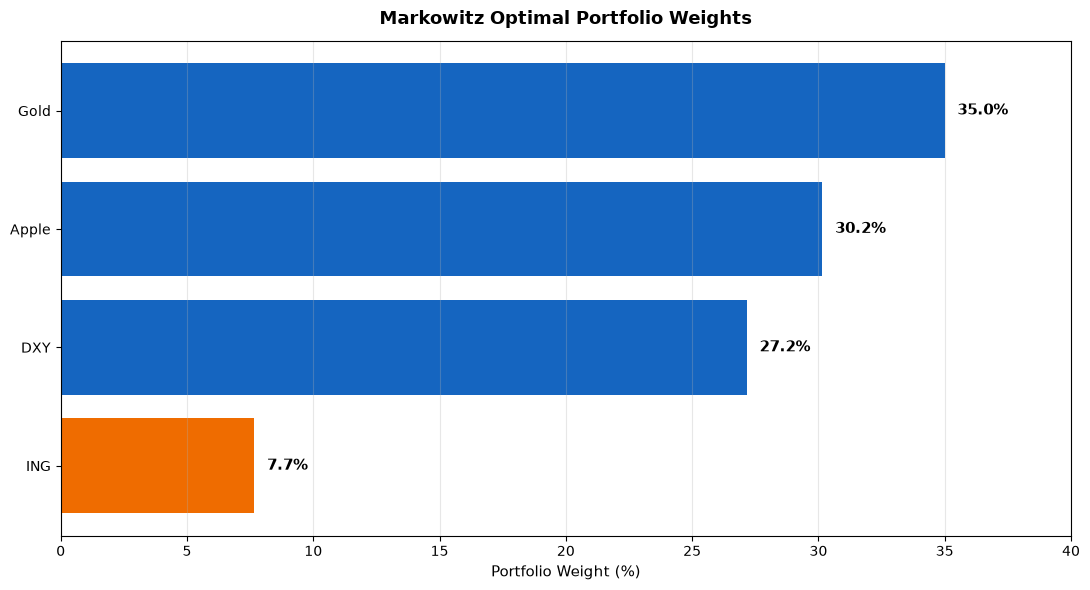

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pypfopt import EfficientFrontier, risk_models, expected_returns

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
monthly = data.resample('ME').last()

mu = expected_returns.mean_historical_return(monthly, frequency=12)
S = risk_models.sample_cov(monthly, frequency=12)

ef = EfficientFrontier(mu, S, weight_bounds=(0, 0.35))
ef.max_sharpe()
weights = ef.clean_weights()
perf = ef.portfolio_performance(verbose=True)

w_df = pd.DataFrame({
    'Weight (%)': {k.replace('_Real', ''): round(v * 100, 2)
                   for k, v in weights.items()}
}).sort_values('Weight (%)', ascending=True)

w_df = w_df[w_df['Weight (%)'] > 0]

print(w_df)


fig, ax = plt.subplots(figsize=(11, 6))

colors = ['#1565c0' if v >= 25 else '#2e7d32' if v >= 10 else '#ef6c00'
          for v in w_df['Weight (%)']]
bars = ax.barh(w_df.index, w_df['Weight (%)'], color=colors)

for bar, val in zip(bars, w_df['Weight (%)']):
    y = bar.get_y() + bar.get_height() / 2
    ax.text(val + 0.5, y, f'{val:.1f}%',
            va='center', ha='left',
            fontsize=11, fontweight='bold')

ax.set_xlabel('Portfolio Weight (%)', fontsize=11)
ax.set_title('Markowitz Optimal Portfolio Weights',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xlim(0, max(w_df['Weight (%)']) + 5)
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('markowitz_weights.png', dpi=300)
plt.show()

### 11. Rebalancing vs Buy & Hold

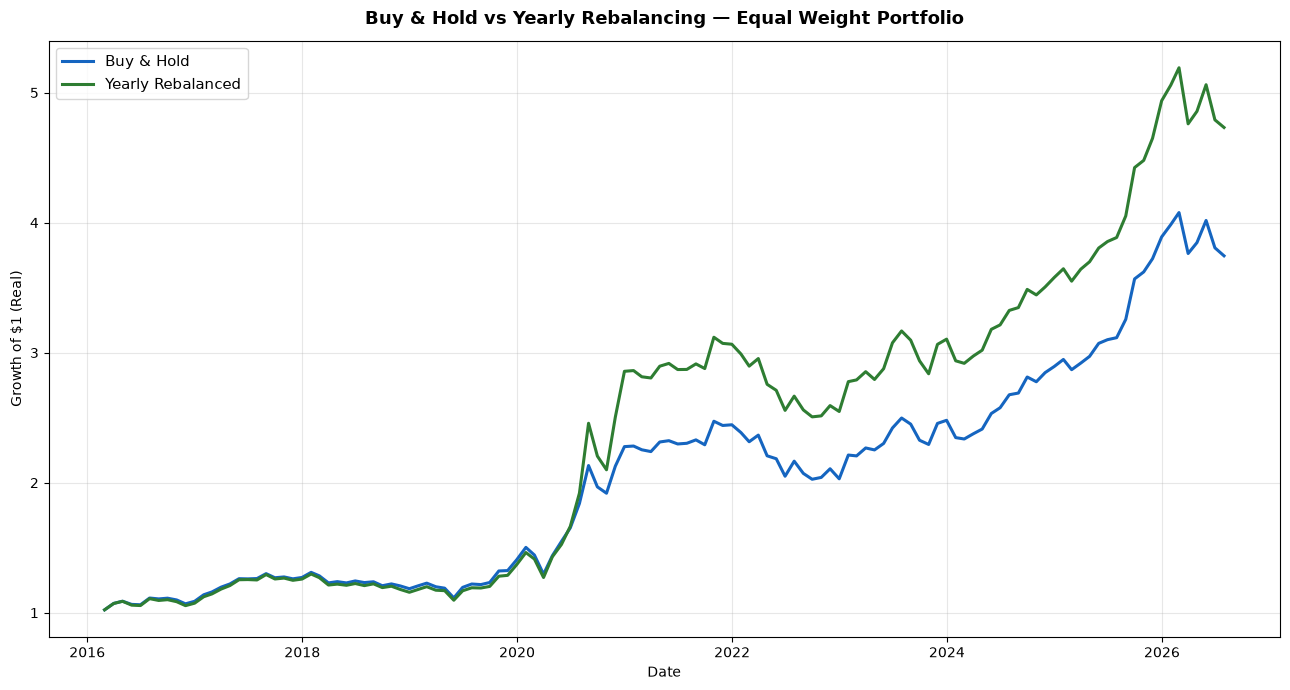

                  Buy & Hold  Rebalanced
Total Return (%)     274.480      373.17
CAGR (%)              13.400       15.95
Volatility (%)        14.300       17.73
Max Drawdown (%)     -18.050      -19.64
Sharpe                 0.937        0.90


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
monthly = data.resample('ME').last()
returns = monthly.pct_change().dropna()

weights = pd.Series([1/8] * 8, index=real_cols)


def buy_and_hold(returns, weights):
    port = (returns * weights).sum(axis=1)
    return (1 + port).cumprod()


def rebalanced(returns, weights, freq='YE'):
    port = pd.Series(index=returns.index, dtype=float)
    current_w = weights.copy()
    rebal_dates = returns.resample(freq).last().index

    for date, row in returns.iterrows():
        port[date] = (row * current_w).sum()
        current_w = current_w * (1 + row)
        current_w = current_w / current_w.sum()
        if date in rebal_dates:
            current_w = weights.copy()

    return (1 + port).cumprod()


bh = buy_and_hold(returns, weights)
rb = rebalanced(returns, weights, freq='YE')

fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(bh.index, bh.values, label='Buy & Hold',
        linewidth=2.2, color='#1565c0')
ax.plot(rb.index, rb.values, label='Yearly Rebalanced',
        linewidth=2.2, color='#2e7d32')

ax.set_ylabel('Growth of $1 (Real)')
ax.set_xlabel('Date')
ax.set_title('Buy & Hold vs Yearly Rebalancing — Equal Weight Portfolio',
             fontsize=13, fontweight='bold', pad=12)
ax.legend(loc='upper left', fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('rebalancing_vs_bh.png', dpi=300)
plt.show()


def stats(series):
    total = series.iloc[-1] - 1
    cagr = series.iloc[-1] ** (12 / len(series)) - 1
    vol = series.pct_change().std() * np.sqrt(12)
    dd = (series / series.cummax() - 1).min()
    sharpe = cagr / vol
    return pd.Series({
        'Total Return (%)': round(total * 100, 2),
        'CAGR (%)': round(cagr * 100, 2),
        'Volatility (%)': round(vol * 100, 2),
        'Max Drawdown (%)': round(dd * 100, 2),
        'Sharpe': round(sharpe, 3)
    })


comparison = pd.DataFrame({
    'Buy & Hold': stats(bh),
    'Rebalanced': stats(rb)
})

print("=" * 50)
print(comparison)
print("=" * 50)

### 12. Final Decision Matrix

             CAGR (%)  Vol (%)  Sharpe  Max DD (%)  VaR 95% (%)  Kurtosis  \
Apple_Real      24.86    28.38   0.876      -38.46        -2.69      7.17   
Tesla_Real      31.34    57.66   0.544      -75.52        -5.34      4.57   
Gold_Real        9.40    16.44   0.572      -31.16        -1.62      9.00   
Silver_Real     10.59    33.37   0.317      -52.34        -3.06     22.24   
ING_Real        12.82    34.27   0.374      -75.28        -3.03     12.51   
DXY_Real        -2.97     6.63  -0.447      -31.18        -0.70      1.82   
CHFUSD_Real     -1.10     7.54  -0.146      -24.75        -0.74      3.97   
EURUSD_Real     -2.74     7.41  -0.370      -36.06        -0.73      2.21   

             Score   Verdict  
Apple_Real    6.50     BUY ✅  
Tesla_Real    5.25   HOLD ⚠️  
Gold_Real     4.75   HOLD ⚠️  
Silver_Real   3.50  WATCH ⚠️  
ING_Real      3.50  WATCH ⚠️  
DXY_Real      0.25   AVOID ❌  
CHFUSD_Real   0.25   AVOID ❌  
EURUSD_Real   0.00   AVOID ❌  


C:\Users\husey\AppData\Local\Temp\ipykernel_6188\1207146615.py:136: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.savefig('final_decision_matrix.png', dpi=300, bbox_inches='tight')
C:\Users\husey\AppData\Local\Temp\ipykernel_6188\1207146615.py:136: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.savefig('final_decision_matrix.png', dpi=300, bbox_inches='tight')
C:\Users\husey\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\husey\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


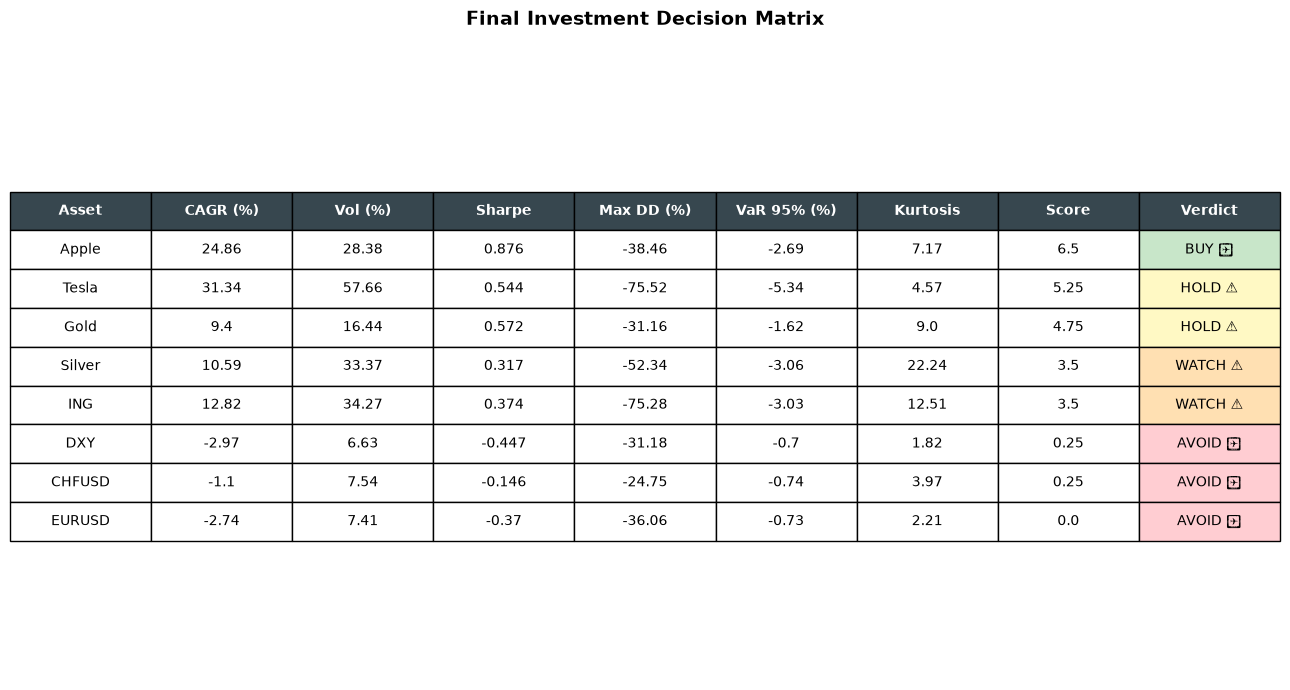

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

real_cols = ['Gold_Real', 'Silver_Real', 'ING_Real',
             'Apple_Real', 'Tesla_Real',
             'DXY_Real', 'EURUSD_Real', 'CHFUSD_Real']

df = df_merged_inflation.copy()

if 'date' in df.columns:
    df['date'] = pd.to_datetime(df['date'])
    df = df.set_index('date')
else:
    df.index = pd.to_datetime(df.index)

df = df.sort_index()

data = df[real_cols].ffill()
monthly = data.resample('ME').last()
daily_returns = data.pct_change().dropna()


def cagr(prices, periods_per_year=12):
    n = len(prices)
    years = n / periods_per_year
    return (prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1


cagr_vals = monthly.apply(lambda x: cagr(x))
vol_annual = daily_returns.std() * np.sqrt(252)
sharpe = cagr_vals / vol_annual
max_dd = (data / data.cummax() - 1).min()
var_95 = daily_returns.quantile(0.05)
kurt = daily_returns.kurtosis()

matrix = pd.DataFrame({
    'CAGR (%)': (cagr_vals * 100).round(2),
    'Vol (%)': (vol_annual * 100).round(2),
    'Sharpe': sharpe.round(3),
    'Max DD (%)': (max_dd * 100).round(2),
    'VaR 95% (%)': (var_95 * 100).round(2),
    'Kurtosis': kurt.round(2)
})


def score_row(row):
    score = 0

    if row['CAGR (%)'] > 25: score += 3
    elif row['CAGR (%)'] > 15: score += 2.5
    elif row['CAGR (%)'] > 10: score += 2
    elif row['CAGR (%)'] > 5: score += 1.5
    elif row['CAGR (%)'] > 2: score += 1
    elif row['CAGR (%)'] > 0: score += 0.5
    else: score -= 1

    if row['Sharpe'] > 0.8: score += 2.5
    elif row['Sharpe'] > 0.6: score += 2
    elif row['Sharpe'] > 0.4: score += 1.5
    elif row['Sharpe'] > 0.2: score += 1
    elif row['Sharpe'] > 0: score += 0.5
    else: score -= 1

    if row['Max DD (%)'] > -20: score += 1
    elif row['Max DD (%)'] > -35: score += 0.75
    elif row['Max DD (%)'] > -50: score += 0.5
    elif row['Max DD (%)'] > -70: score += 0.25

    if row['VaR 95% (%)'] > -1.5: score += 0.75
    elif row['VaR 95% (%)'] > -3: score += 0.5
    elif row['VaR 95% (%)'] > -5: score += 0.25

    if row['Kurtosis'] < 6: score += 0.75
    elif row['Kurtosis'] < 10: score += 0.5
    elif row['Kurtosis'] < 15: score += 0.25

    return round(score, 2)


def verdict(score):
    if score >= 6: return 'BUY ✅'
    elif score >= 4.5: return 'HOLD ⚠️'
    elif score >= 2.5: return 'WATCH ⚠️'
    else: return 'AVOID ❌'


matrix['Score'] = matrix.apply(score_row, axis=1)
matrix['Verdict'] = matrix['Score'].apply(verdict)
matrix = matrix.sort_values('Score', ascending=False)

print("=" * 90)
print(matrix)
print("=" * 90)

matrix.to_csv('final_decision_matrix.csv')


fig, ax = plt.subplots(figsize=(13, 7))
ax.axis('tight')
ax.axis('off')

table_data = matrix.reset_index()
table_data.columns = ['Asset'] + list(matrix.columns)
table_data['Asset'] = table_data['Asset'].str.replace('_Real', '')

colors_map = {
    'BUY ✅': '#c8e6c9',
    'HOLD ⚠️': '#fff9c4',
    'WATCH ⚠️': '#ffe0b2',
    'AVOID ❌': '#ffcdd2'
}
cell_colors = [['white'] * len(table_data.columns)
               for _ in range(len(table_data))]
for i, v in enumerate(matrix['Verdict'].values):
    cell_colors[i][-1] = colors_map[v]

table = ax.table(
    cellText=table_data.values,
    colLabels=table_data.columns,
    cellColours=cell_colors,
    cellLoc='center',
    loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

for j in range(len(table_data.columns)):
    table[(0, j)].set_facecolor('#37474f')
    table[(0, j)].set_text_props(color='white', fontweight='bold')

ax.set_title('Final Investment Decision Matrix',
             fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('final_decision_matrix.png', dpi=300, bbox_inches='tight')
plt.show()